In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('D:\\AI\\workspace\\project\\Dibetes\\diabetes_risk_prediction_dataset.csv')

In [6]:
print(df.head())

   Patient_ID   Age Gender        Country  Height_cm  Weight_kg   BMI  \
0           1  32.0   Male         Mexico      182.1       65.8  19.8   
1           2  42.0  Other   Saudi Arabia      148.5      101.2  45.9   
2           3  89.0  Other      Argentina      158.1        NaN  37.9   
3           4  87.0  Other  United States      190.9       95.9  26.3   
4           5  27.0  Other      Australia      156.9      101.9  41.4   

   Waist_Circumference_cm  Blood_Glucose  HbA1c  ...  Fatty_Liver  PCOS  \
0                    71.2           88.4   10.4  ...          Yes    No   
1                   121.8          247.3   11.3  ...          Yes   Yes   
2                   131.8          141.9    6.3  ...          Yes    No   
3                    99.1           90.1    7.4  ...           No    No   
4                    77.1           93.8   12.0  ...          Yes   Yes   

   Medication_Adherence   Work_Type  Residence_Type  Daily_Water_Intake_L  \
0                  Good     Retir

In [7]:
print(df.shape)

(50000, 41)


In [8]:
print(df.columns)

Index(['Patient_ID', 'Age', 'Gender', 'Country', 'Height_cm', 'Weight_kg',
       'BMI', 'Waist_Circumference_cm', 'Blood_Glucose', 'HbA1c',
       'Fasting_Blood_Sugar', 'Insulin_Level', 'Blood_Pressure_Systolic',
       'Blood_Pressure_Diastolic', 'Total_Cholesterol', 'HDL', 'LDL',
       'Triglycerides', 'Heart_Rate', 'Physical_Activity_Level',
       'Exercise_Hours_Per_Week', 'Daily_Walking_Minutes', 'Diet_Quality',
       'Sugar_Intake_Level', 'Sleep_Hours', 'Stress_Level', 'Smoking_Status',
       'Alcohol_Consumption', 'Family_History_Diabetes', 'Hypertension',
       'Heart_Disease', 'Fatty_Liver', 'PCOS', 'Medication_Adherence',
       'Work_Type', 'Residence_Type', 'Daily_Water_Intake_L',
       'Diabetes_Risk_Score', 'AI_Health_Recommendation',
       'Doctor_Consultation_Needed', 'Diabetes_Risk'],
      dtype='str')


In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 41 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Patient_ID                  50000 non-null  int64  
 1   Age                         49503 non-null  float64
 2   Gender                      50000 non-null  str    
 3   Country                     50000 non-null  str    
 4   Height_cm                   47055 non-null  float64
 5   Weight_kg                   47038 non-null  float64
 6   BMI                         50000 non-null  float64
 7   Waist_Circumference_cm      50000 non-null  float64
 8   Blood_Glucose               49041 non-null  float64
 9   HbA1c                       48026 non-null  float64
 10  Fasting_Blood_Sugar         50000 non-null  float64
 11  Insulin_Level               50000 non-null  float64
 12  Blood_Pressure_Systolic     50000 non-null  int64  
 13  Blood_Pressure_Diastolic    50000 non-null

In [10]:
print(df.describe())

         Patient_ID           Age     Height_cm     Weight_kg           BMI  \
count  50000.000000  49503.000000  47055.000000  47038.000000  50000.000000   
mean   25000.500000     53.871099    170.018814     87.457003     30.924056   
std    14433.901067     21.130148     14.457787     24.500358     10.290091   
min        1.000000     18.000000    145.000000     45.000000     11.900000   
25%    12500.750000     35.000000    157.600000     66.300000     22.700000   
50%    25000.500000     54.000000    170.000000     87.300000     30.000000   
75%    37500.250000     72.000000    182.600000    108.600000     37.800000   
max    50000.000000     90.000000    195.000000    130.000000     61.700000   

       Waist_Circumference_cm  Blood_Glucose         HbA1c  \
count            50000.000000   49041.000000  48026.000000   
mean                99.960790     159.905245      8.488061   
std                 23.086579      52.040575      2.313758   
min                 60.000000      70.00

In [11]:
print(df.duplicated().sum())

0


In [12]:
#Display diabetes risk categories
print(df['Diabetes_Risk'].value_counts())

Diabetes_Risk
High        36593
Moderate    12937
Low           470
Name: count, dtype: int64


In [13]:
# Target variable percentages
print(df['Diabetes_Risk'].value_counts(normalize=True) * 100)

Diabetes_Risk
High        73.186
Moderate    25.874
Low          0.940
Name: proportion, dtype: float64


In [14]:
# To find missing values
missing = df.isnull().sum()
print(missing)

Patient_ID                       0
Age                            497
Gender                           0
Country                          0
Height_cm                     2945
Weight_kg                     2962
BMI                              0
Waist_Circumference_cm           0
Blood_Glucose                  959
HbA1c                         1974
Fasting_Blood_Sugar              0
Insulin_Level                    0
Blood_Pressure_Systolic          0
Blood_Pressure_Diastolic         0
Total_Cholesterol             1000
HDL                           1000
LDL                           1000
Triglycerides                 1000
Heart_Rate                       0
Physical_Activity_Level        500
Exercise_Hours_Per_Week       1992
Daily_Walking_Minutes         1964
Diet_Quality                     0
Sugar_Intake_Level               0
Sleep_Hours                   2017
Stress_Level                     0
Smoking_Status                   0
Alcohol_Consumption              0
Family_History_Diabe

In [15]:
# Total missing values
total_missing = df.isnull().sum().sum()
print("Total Missing Values:", total_missing)

Total Missing Values: 20810


In [17]:
missing_summary = pd.DataFrame({'Missing_Count': df.isnull().sum(),'Missing_Percentage': df.isnull().mean() * 100})
missing_summary = missing_summary.sort_values(by='Missing_Percentage',ascending=False)
print(missing_summary)

                            Missing_Count  Missing_Percentage
Weight_kg                            2962               5.924
Height_cm                            2945               5.890
Sleep_Hours                          2017               4.034
Exercise_Hours_Per_Week              1992               3.984
HbA1c                                1974               3.948
Daily_Walking_Minutes                1964               3.928
HDL                                  1000               2.000
LDL                                  1000               2.000
Triglycerides                        1000               2.000
Medication_Adherence                 1000               2.000
Total_Cholesterol                    1000               2.000
Blood_Glucose                         959               1.918
Physical_Activity_Level               500               1.000
Age                                   497               0.994
Patient_ID                              0               0.000
Gender  

In [18]:
#Fill the missing values with median

num_cols = df.select_dtypes(include=np.number).columns
for col in num_cols:
    median_value = df[col].median()
    df[col] = df[col].fillna(median_value)

In [19]:
# Find categorical missing values

cat_cols = df.select_dtypes(include=['object','str']).columns

for col in cat_cols:
    mode_value = df[col].mode()
    if not mode_value.empty:
        df[col] = df[col].fillna(mode_value.iloc[0])

In [22]:
# To find duplicate records
duplicates = df[df.duplicated()]
print(duplicates.head())

Empty DataFrame
Columns: [Patient_ID, Age, Gender, Country, Height_cm, Weight_kg, BMI, Waist_Circumference_cm, Blood_Glucose, HbA1c, Fasting_Blood_Sugar, Insulin_Level, Blood_Pressure_Systolic, Blood_Pressure_Diastolic, Total_Cholesterol, HDL, LDL, Triglycerides, Heart_Rate, Physical_Activity_Level, Exercise_Hours_Per_Week, Daily_Walking_Minutes, Diet_Quality, Sugar_Intake_Level, Sleep_Hours, Stress_Level, Smoking_Status, Alcohol_Consumption, Family_History_Diabetes, Hypertension, Heart_Disease, Fatty_Liver, PCOS, Medication_Adherence, Work_Type, Residence_Type, Daily_Water_Intake_L, Diabetes_Risk_Score, AI_Health_Recommendation, Doctor_Consultation_Needed, Diabetes_Risk]
Index: []

[0 rows x 41 columns]


In [23]:
# Remove duplicated records
df = df.drop_duplicates()
print(df.shape)

(50000, 41)


In [24]:
#Numerical columns
numerical_columns = df.select_dtypes(include=['int64', 'float64']).columns
print(numerical_columns)

#Categorical columns
categorical_columns = df.select_dtypes(include=['object', 'category']).columns
print(categorical_columns)

print("Numerical Columns:", len(numerical_columns))

print("Categorical Columns:", len(categorical_columns))

Index(['Patient_ID', 'Age', 'Height_cm', 'Weight_kg', 'BMI',
       'Waist_Circumference_cm', 'Blood_Glucose', 'HbA1c',
       'Fasting_Blood_Sugar', 'Insulin_Level', 'Blood_Pressure_Systolic',
       'Blood_Pressure_Diastolic', 'Total_Cholesterol', 'HDL', 'LDL',
       'Triglycerides', 'Heart_Rate', 'Exercise_Hours_Per_Week',
       'Daily_Walking_Minutes', 'Sleep_Hours', 'Daily_Water_Intake_L',
       'Diabetes_Risk_Score'],
      dtype='str')
Index(['Gender', 'Country', 'Physical_Activity_Level', 'Diet_Quality',
       'Sugar_Intake_Level', 'Stress_Level', 'Smoking_Status',
       'Alcohol_Consumption', 'Family_History_Diabetes', 'Hypertension',
       'Heart_Disease', 'Fatty_Liver', 'PCOS', 'Medication_Adherence',
       'Work_Type', 'Residence_Type', 'AI_Health_Recommendation',
       'Doctor_Consultation_Needed', 'Diabetes_Risk'],
      dtype='str')
Numerical Columns: 22
Categorical Columns: 19


C:\Users\surji\AppData\Local\Temp\ipykernel_6356\3067078610.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(include=['object', 'category']).columns


In [25]:
# Check incorrect values
# Check age

if 'Age' in df.columns:

    print("Negative Age:",(df['Age'] < 0).sum())

    print("Age above 120:",(df['Age'] > 120).sum())

# Check BMI

if 'BMI' in df.columns:
    print("BMI zero or negative:",(df['BMI'] <= 0).sum())

# Check glucose

if 'Blood_Glucose' in df.columns:
    print("Invalid Glucose:",(df['Blood_Glucose'] <= 0).sum())

Negative Age: 0
Age above 120: 0
BMI zero or negative: 0
Invalid Glucose: 0


In [26]:
# Search for possible ID's and columns

possible_columns = [col for col in df.columns
    if any(word in col.lower()
           for word in ['id', 'score', 'recommendation'])]
print(possible_columns)

['Patient_ID', 'Triglycerides', 'Residence_Type', 'Diabetes_Risk_Score', 'AI_Health_Recommendation']


In [27]:
# Check the target coloumn
print(df['Diabetes_Risk'].value_counts(dropna=False))

Diabetes_Risk
High        36593
Moderate    12937
Low           470
Name: count, dtype: int64


In [28]:


target_col = 'Diabetes_Risk'

# Identify ID columns
id_cols = [col for col in df.columns if col.lower().endswith('_id') or col.lower() == 'id']

# Identify numerical columns
num_cols = df.select_dtypes( include=np.number).columns.tolist()

# Exclude IDs and target from automatic imputation
num_cols = [ col for col in num_cols if col not in id_cols + [target_col]]

# Fill numerical missing values with median
for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

# Identify categorical columns
cat_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()

# Exclude target and IDs
cat_cols = [col for col in cat_cols if col not in id_cols + [target_col]]

# Fill categorical missing values with mode
for col in cat_cols:
    mode = df[col].mode()

    if not mode.empty:
        df[col] = df[col].fillna(mode.iloc[0])

print("Missing values after cleaning:")
print(df.isnull().sum())

C:\Users\surji\AppData\Local\Temp\ipykernel_6356\1245763859.py:17: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()


Missing values after cleaning:
Patient_ID                    0
Age                           0
Gender                        0
Country                       0
Height_cm                     0
Weight_kg                     0
BMI                           0
Waist_Circumference_cm        0
Blood_Glucose                 0
HbA1c                         0
Fasting_Blood_Sugar           0
Insulin_Level                 0
Blood_Pressure_Systolic       0
Blood_Pressure_Diastolic      0
Total_Cholesterol             0
HDL                           0
LDL                           0
Triglycerides                 0
Heart_Rate                    0
Physical_Activity_Level       0
Exercise_Hours_Per_Week       0
Daily_Walking_Minutes         0
Diet_Quality                  0
Sugar_Intake_Level            0
Sleep_Hours                   0
Stress_Level                  0
Smoking_Status                0
Alcohol_Consumption           0
Family_History_Diabetes       0
Hypertension                  0
Heart_Dis

In [31]:
print(df.isnull().sum().sum())

print("Duplicates:", df.duplicated().sum())

print("Original Shape:", df.shape)

0
Duplicates: 0
Original Shape: (50000, 41)


In [32]:
print(df.shape)
print(df.isnull().sum())
print(df['Diabetes_Risk'].value_counts(dropna=False))

(50000, 41)
Patient_ID                    0
Age                           0
Gender                        0
Country                       0
Height_cm                     0
Weight_kg                     0
BMI                           0
Waist_Circumference_cm        0
Blood_Glucose                 0
HbA1c                         0
Fasting_Blood_Sugar           0
Insulin_Level                 0
Blood_Pressure_Systolic       0
Blood_Pressure_Diastolic      0
Total_Cholesterol             0
HDL                           0
LDL                           0
Triglycerides                 0
Heart_Rate                    0
Physical_Activity_Level       0
Exercise_Hours_Per_Week       0
Daily_Walking_Minutes         0
Diet_Quality                  0
Sugar_Intake_Level            0
Sleep_Hours                   0
Stress_Level                  0
Smoking_Status                0
Alcohol_Consumption           0
Family_History_Diabetes       0
Hypertension                  0
Heart_Disease               

EDA Analysis

In [ ]:
# Target variable analysis
print(df['Diabetes_Risk'].value_counts(dropna=False))

Diabetes_Risk
High        36593
Moderate    12937
Low           470
Name: count, dtype: int64


In [34]:
risk_percentage = (df['Diabetes_Risk'].value_counts(normalize=True, dropna=False) * 100)

print(risk_percentage)

Diabetes_Risk
High        73.186
Moderate    25.874
Low          0.940
Name: proportion, dtype: float64


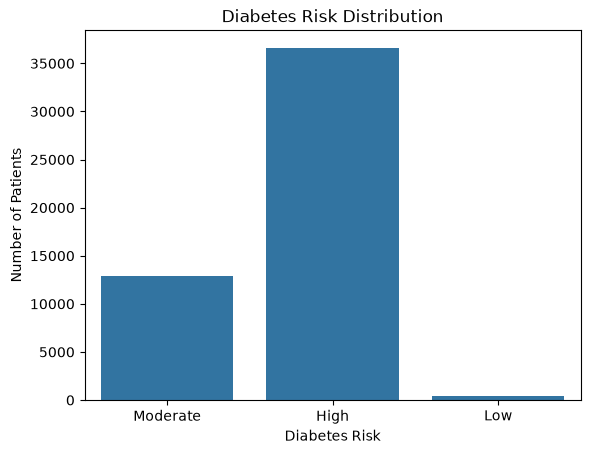

In [35]:
# Diabetes Risk visualization

sns.countplot(data=df, x='Diabetes_Risk')

plt.title('Diabetes Risk Distribution')
plt.xlabel('Diabetes Risk')
plt.ylabel('Number of Patients')
plt.show()

In [37]:
# Numerical column analysis

# Find numerical columns

numerical_columns = df.select_dtypes(include=np.number).columns

print(numerical_columns)

print(df[numerical_columns].describe())

Index(['Patient_ID', 'Age', 'Height_cm', 'Weight_kg', 'BMI',
       'Waist_Circumference_cm', 'Blood_Glucose', 'HbA1c',
       'Fasting_Blood_Sugar', 'Insulin_Level', 'Blood_Pressure_Systolic',
       'Blood_Pressure_Diastolic', 'Total_Cholesterol', 'HDL', 'LDL',
       'Triglycerides', 'Heart_Rate', 'Exercise_Hours_Per_Week',
       'Daily_Walking_Minutes', 'Sleep_Hours', 'Daily_Water_Intake_L',
       'Diabetes_Risk_Score'],
      dtype='str')
         Patient_ID          Age     Height_cm     Weight_kg           BMI  \
count  50000.000000  50000.00000  50000.000000  50000.000000  50000.000000   
mean   25000.500000     53.87238    170.017706     87.447702     30.924056   
std    14433.901067     21.02487     14.025535     23.763593     10.290091   
min        1.000000     18.00000    145.000000     45.000000     11.900000   
25%    12500.750000     36.00000    158.300000     67.700000     22.700000   
50%    25000.500000     54.00000    170.000000     87.300000     30.000000   
75% 

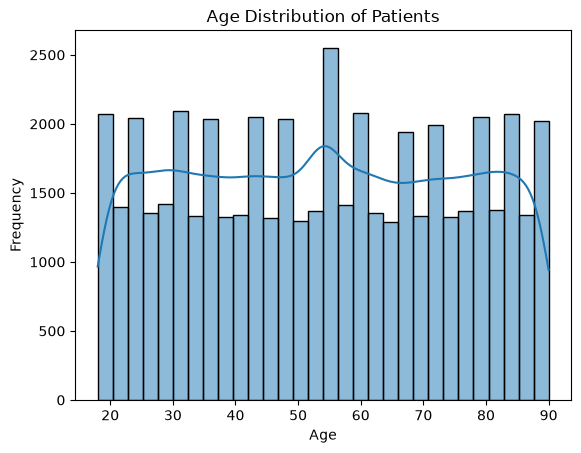

In [38]:
# Age dependancy

sns.histplot(data=df, x='Age', bins=30, kde=True)

plt.title('Age Distribution of Patients')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.show()

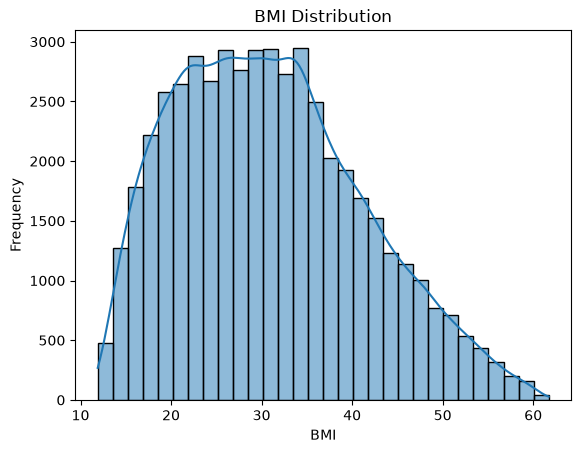

In [39]:
# BMI distribution

sns.histplot(data=df, x='BMI', bins=30, kde=True)

plt.title('BMI Distribution')
plt.xlabel('BMI')
plt.ylabel('Frequency')
plt.show()

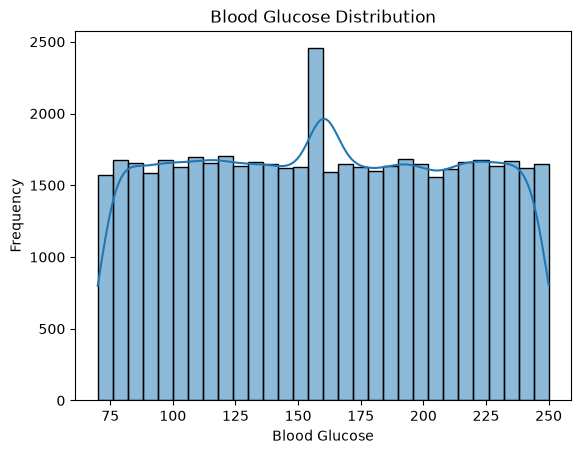

In [40]:
# Blood glucose analysis

sns.histplot( data=df,x='Blood_Glucose',bins=30,kde=True)

plt.title('Blood Glucose Distribution')
plt.xlabel('Blood Glucose')
plt.ylabel('Frequency')
plt.show()

In [41]:
# Categorical column analysis
# Gender

print(df['Gender'].value_counts())

Gender
Male      16718
Other     16677
Female    16605
Name: count, dtype: int64


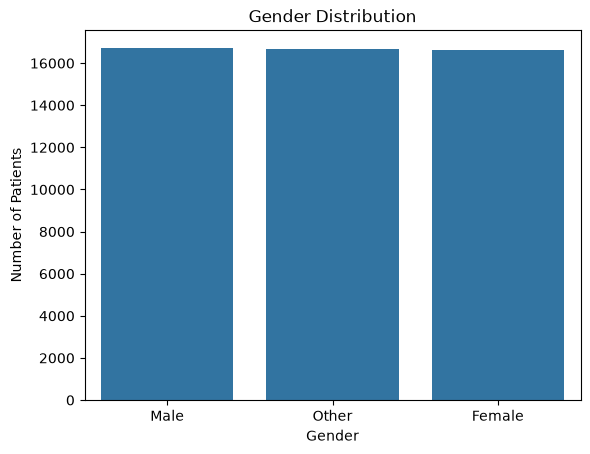

In [ ]:
# Bar Chart

sns.countplot(data=df, x='Gender')

plt.title('Gender Distribution')
plt.xlabel('Gender')
plt.ylabel('Number of Patients')
plt.show()

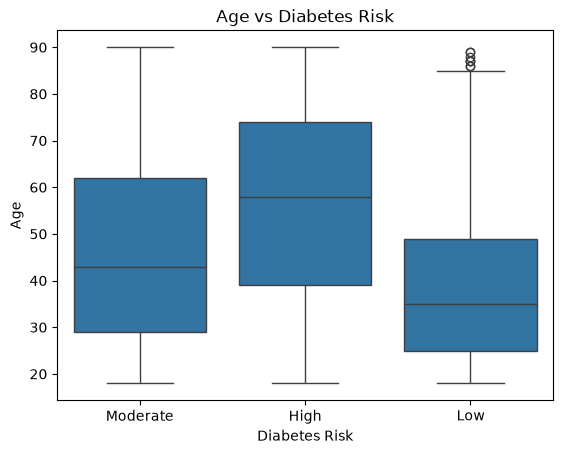

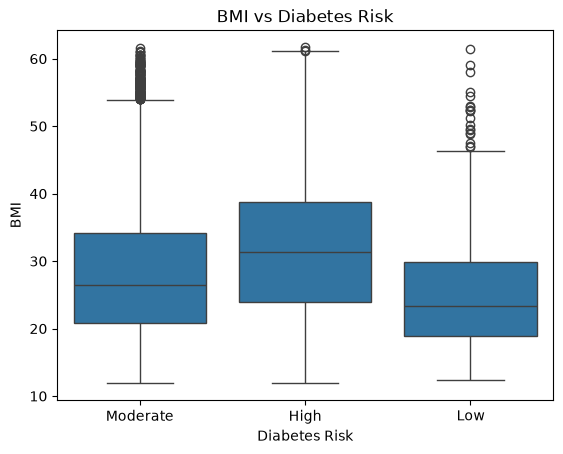

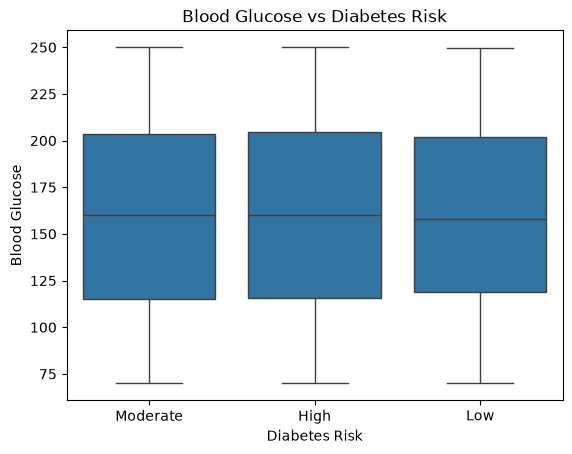

In [45]:
# Age Vs diabetes risk
sns.boxplot(data=df,x='Diabetes_Risk',y='Age')

plt.title('Age vs Diabetes Risk')
plt.xlabel('Diabetes Risk')
plt.ylabel('Age')
plt.show()

# BMI Vs Diabetes risk

sns.boxplot(data=df,x='Diabetes_Risk',y='BMI')

plt.title('BMI vs Diabetes Risk')
plt.xlabel('Diabetes Risk')
plt.ylabel('BMI')
plt.show()

# Blood glucose Vs Diabetes risk
sns.boxplot(data=df,x='Diabetes_Risk',y='Blood_Glucose')

plt.title('Blood Glucose vs Diabetes Risk')
plt.xlabel('Diabetes Risk')
plt.ylabel('Blood Glucose')
plt.show()

In [46]:
# Correlation analysis

correlation = df.select_dtypes(include=np.number).corr()

print(correlation)

                          Patient_ID       Age  Height_cm  Weight_kg  \
Patient_ID                  1.000000 -0.005015  -0.005786  -0.002954   
Age                        -0.005015  1.000000  -0.007627  -0.002852   
Height_cm                  -0.005786 -0.007627   1.000000  -0.002258   
Weight_kg                  -0.002954 -0.002852  -0.002258   1.000000   
BMI                        -0.000360 -0.001115  -0.500618   0.817881   
Waist_Circumference_cm     -0.000235 -0.000889   0.005814  -0.004344   
Blood_Glucose               0.005434  0.000799   0.003294  -0.003925   
HbA1c                      -0.014371  0.009798  -0.000151   0.001370   
Fasting_Blood_Sugar         0.003443  0.007296   0.000944   0.001325   
Insulin_Level               0.006592  0.003022   0.001884   0.009559   
Blood_Pressure_Systolic     0.003366  0.003102   0.005827  -0.001675   
Blood_Pressure_Diastolic    0.004377  0.004937   0.002372  -0.003337   
Total_Cholesterol           0.005340 -0.009587   0.004953  -0.00

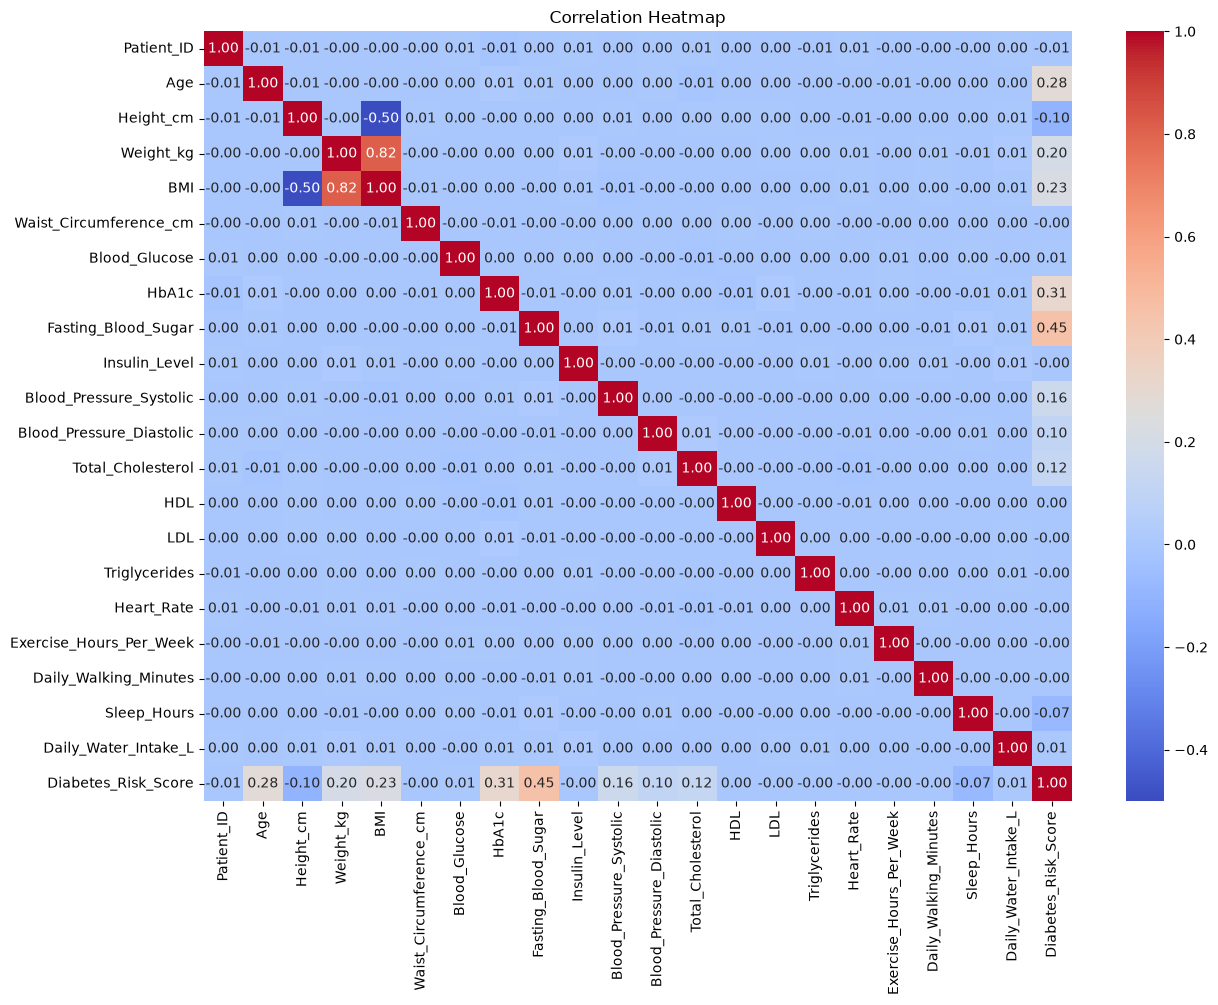

In [47]:
plt.figure(figsize=(14, 10))

sns.heatmap(correlation,annot=True,cmap='coolwarm',fmt='.2f')

plt.title('Correlation Heatmap')
plt.show()

In [8]:
print("Dataset Shape:")
print(df.shape)

print("\nDiabetes Risk Distribution:")
print(df['Diabetes_Risk'].value_counts(dropna=False))

print("\nNumerical Columns:")
print(df.select_dtypes(include=np.number).columns.tolist())

print("\nCorrelation:")
print(df.select_dtypes(include=np.number).corr())

Dataset Shape:
(50000, 41)

Diabetes Risk Distribution:
Diabetes_Risk
High        36593
Moderate    12937
Low           470
Name: count, dtype: int64

Numerical Columns:
['Patient_ID', 'Age', 'Height_cm', 'Weight_kg', 'BMI', 'Waist_Circumference_cm', 'Blood_Glucose', 'HbA1c', 'Fasting_Blood_Sugar', 'Insulin_Level', 'Blood_Pressure_Systolic', 'Blood_Pressure_Diastolic', 'Total_Cholesterol', 'HDL', 'LDL', 'Triglycerides', 'Heart_Rate', 'Exercise_Hours_Per_Week', 'Daily_Walking_Minutes', 'Sleep_Hours', 'Daily_Water_Intake_L', 'Diabetes_Risk_Score']

Correlation:
                          Patient_ID       Age  Height_cm  Weight_kg  \
Patient_ID                  1.000000 -0.005045  -0.005963  -0.003046   
Age                        -0.005045  1.000000  -0.007902  -0.002954   
Height_cm                  -0.005963 -0.007902   1.000000  -0.002391   
Weight_kg                  -0.003046 -0.002954  -0.002391   1.000000   
BMI                        -0.000360 -0.001118  -0.516150   0.843427   
Wa

    Age Gender        Country  Height_cm  Weight_kg   BMI  \
0  32.0   Male         Mexico      182.1       65.8  19.8   
1  42.0  Other   Saudi Arabia      148.5      101.2  45.9   
2  89.0  Other      Argentina      158.1        NaN  37.9   
3  87.0  Other  United States      190.9       95.9  26.3   
4  27.0  Other      Australia      156.9      101.9  41.4   

   Waist_Circumference_cm  Blood_Glucose  HbA1c  Fasting_Blood_Sugar  ...  \
0                    71.2           88.4   10.4                149.5  ...   
1                   121.8          247.3   11.3                199.3  ...   
2                   131.8          141.9    6.3                219.6  ...   
3                    99.1           90.1    7.4                217.7  ...   
4                    77.1           93.8   12.0                153.5  ...   

   Hypertension  Heart_Disease  Fatty_Liver  PCOS  Medication_Adherence  \
0            No            Yes          Yes    No                  Good   
1            No     

C:\Users\surji\AppData\Local\Temp\ipykernel_25264\1544532204.py:31: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=['object', 'category', 'bool']).columns


         model  accuracy  precision  Recall  F1 Score
0  Naive Bayes       1.0        1.0     1.0       1.0
1  Naive Bayes       1.0        1.0     1.0       1.0
2  Naive Bayes       1.0        1.0     1.0       1.0
3  Naive Bayes       1.0        1.0     1.0       1.0
4  Naive Bayes       1.0        1.0     1.0       1.0
5  Naive Bayes       1.0        1.0     1.0       1.0


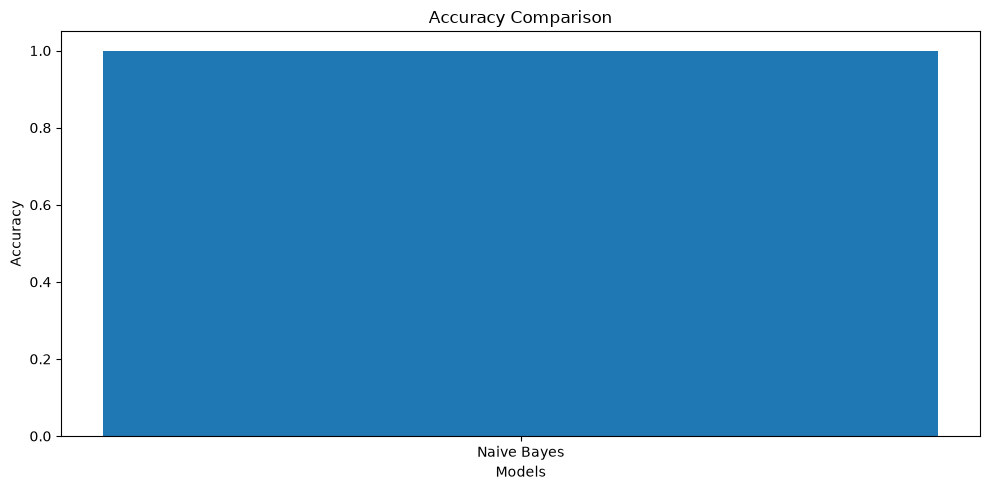

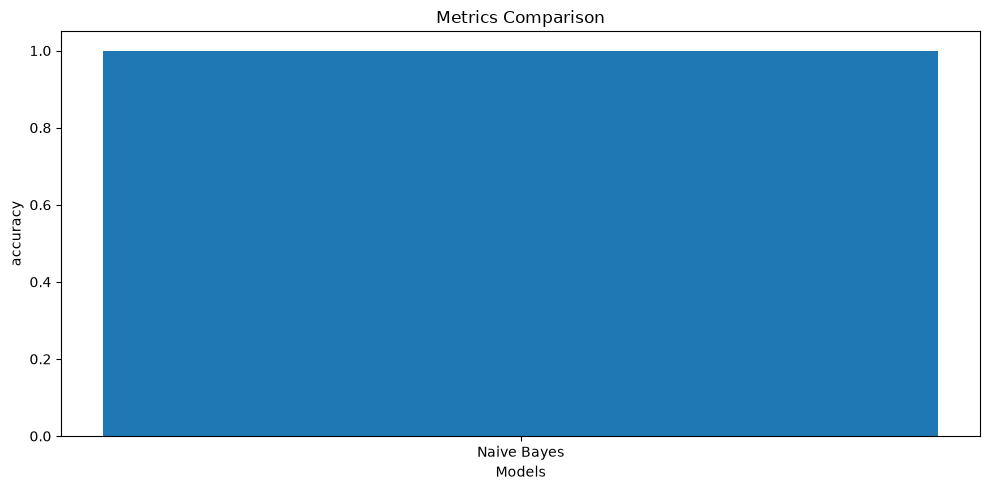

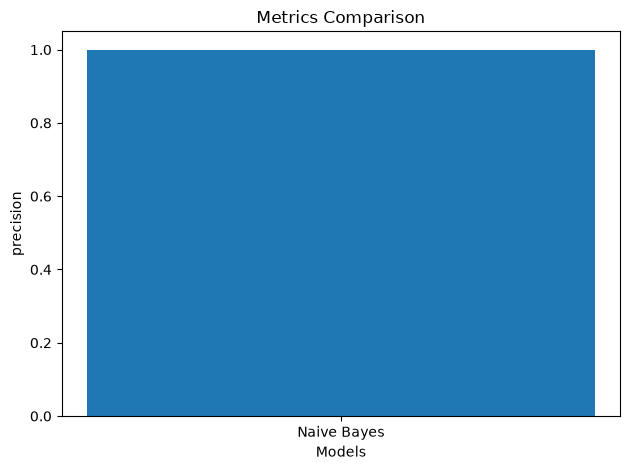

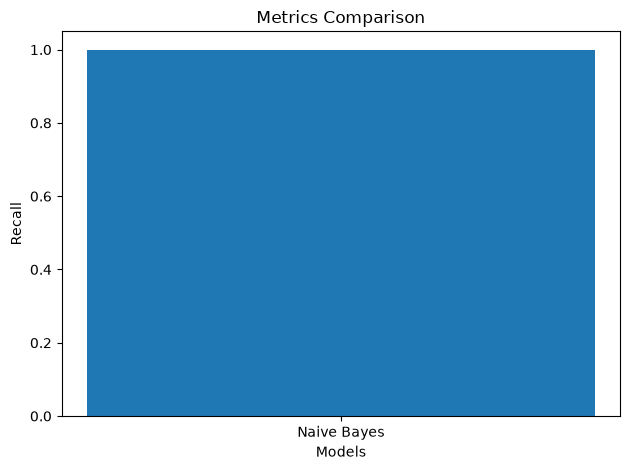

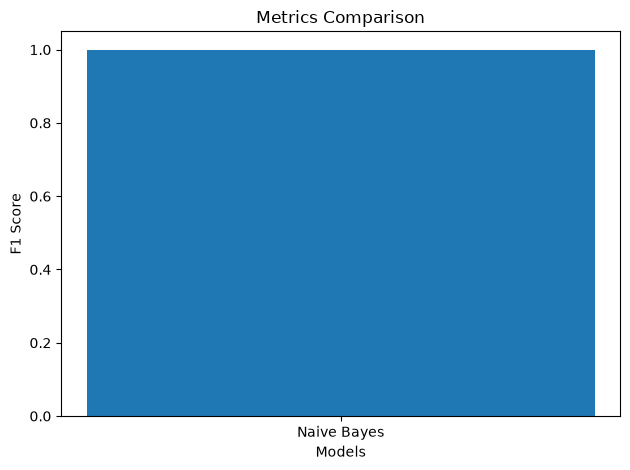

Best Model: Naive Bayes


In [19]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score)
import matplotlib.pyplot as plt


X=df.drop(columns=['Patient_ID','Diabetes_Risk','Diabetes_Risk_Score'])
y=df['Diabetes_Risk']

print(X.head())

print("Result")

print(y.head(10))

# Identify numerical and categorical columns
num_cols = X.select_dtypes(include=['int64', 'float64']).columns

cat_cols = X.select_dtypes(include=['object', 'category', 'bool']).columns

print("Numerical Columns:", list(num_cols))
print("Categorical Columns:", list(cat_cols))

# Numerical preprocessing
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical preprocessing
cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer([
    ('num', num_pipeline, num_cols),
    ('cat', cat_pipeline, cat_cols)
])

X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
models={'Logistic Regression':LogisticRegression(max_iter=2000),'KNN':make_pipeline(StandardScaler(),KNeighborsClassifier(n_neighbors=5)),'DecisionTree':DecisionTreeClassifier(random_state=42),'Random Forest':RandomForestClassifier(random_state=42,n_estimators=5),'SVM':make_pipeline(StandardScaler(),SVC()),'Naive Bayes':GaussianNB()}

results=[]
for name,model in models.items():
    for name, model in models.items():

        pipeline = Pipeline([
        ('preprocessing', preprocessor),
        ('classifier', model)
    ])

    pipeline.fit(X_train, y_train)
    #model.fit(X_train,y_train)
    y_pred=pipeline.predict(X_test)
    accuracy=accuracy_score(y_test,y_pred)
    precision=precision_score(y_test,y_pred,average='macro')
    recall=recall_score(y_test,y_pred,average='macro')
    f1=f1_score(y_test,y_pred,average='macro')
    results.append({'model':name,'accuracy':accuracy,'precision':precision,'Recall':recall,'F1 Score':f1})
res=pd.DataFrame(results)
#print(res)
res=res.sort_values(by='accuracy',ascending=False)
print(res)

plt.figure(figsize=(10,5))
plt.bar(res['model'],res['accuracy'])
plt.xlabel('Models')
plt.ylabel('Accuracy')
plt.xticks()
plt.title('Accuracy Comparison')
plt.tight_layout()
plt.show()

plt.figure(figsize=(10,5))
metrics=['accuracy','precision','Recall','F1 Score']
for i in metrics:
    plt.bar(res['model'],res[i])
    plt.xlabel('Models')
    plt.ylabel(i)
    plt.xticks()
    plt.title('Metrics Comparison')
    plt.tight_layout()
    plt.show()

# Best Model

best_model=res.iloc[0]['model']
print('Best Model:',best_model)

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# 1. Separate Features and Target

X = df.drop(columns=[
    'Patient_ID',
    'Diabetes_Risk',
    'Diabetes_Risk_Score'
])

y = df['Diabetes_Risk']

print(X.head())
print("Result")
print(y.head(10))


# 2. Identify Numerical and Categorical Columns

num_cols = X.select_dtypes(
    include=['int64', 'float64']
).columns

cat_cols = X.select_dtypes(
    include=['object', 'category', 'bool']
).columns

print("Numerical Columns:", list(num_cols))
print("Categorical Columns:", list(cat_cols))


# 3. Numerical Preprocessing

num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])


# 4. Categorical Preprocessing

cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(
        handle_unknown='ignore',
        sparse_output=False
    ))
])


# 5. Combine Preprocessing

preprocessor = ColumnTransformer([
    ('num', num_pipeline, num_cols),
    ('cat', cat_pipeline, cat_cols)
])


# 6. Train Test Split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


# 7. Create Machine Learning Models

models = {
    'Logistic Regression': LogisticRegression(max_iter=2000),

    'KNN': KNeighborsClassifier(n_neighbors=5),

    'Decision Tree': DecisionTreeClassifier(random_state=42),

    'Random Forest': RandomForestClassifier(
        random_state=42,
        n_estimators=100,
        n_jobs=-1
    ),

    'SVM': SVC(),

    'Naive Bayes': GaussianNB()
}


# 8. Model Comparison

results = []

for name, model in models.items():

    pipeline = Pipeline([
        ('preprocessing', preprocessor),
        ('classifier', model)
    ])

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test, y_pred,
        average='macro',
        zero_division=0
    )

    recall = recall_score(
        y_test, y_pred,
        average='macro',
        zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred,
        average='macro',
        zero_division=0
    )

    results.append({
        'Model': name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1 Score': f1
    })


# 9. Display Results

res = pd.DataFrame(results)

res = res.sort_values(
    by='Accuracy',
    ascending=False
)

print("\nMODEL PERFORMANCE COMPARISON")

print(res.round(4).to_string(index=False))


# 10. Accuracy Comparison Chart

plt.figure(figsize=(12, 6))

plt.bar(res['Model'], res['Accuracy'])

plt.xlabel('Models')
plt.ylabel('Accuracy')
plt.title('Diabetes Risk - Accuracy Comparison')

plt.ylim(0, 1.1)
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()


# 11. Performance Metrics Comparison

metrics = ['Accuracy', 'Precision', 'Recall', 'F1 Score']

res.set_index('Model')[metrics].plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title('Diabetes Risk - Performance Metrics Comparison')
plt.xlabel('Machine Learning Models')
plt.ylabel('Score')

plt.ylim(0, 1.1)
plt.xticks(rotation=30)

plt.legend(title='Metrics')
plt.tight_layout()
plt.show()


# 12. Best Model

best_model = res.iloc[0]['Model']

print("\nBest Model:", best_model)
print("Best Accuracy:", round(res.iloc[0]['Accuracy'], 4))

    Age Gender        Country  Height_cm  Weight_kg   BMI  \
0  32.0   Male         Mexico      182.1       65.8  19.8   
1  42.0  Other   Saudi Arabia      148.5      101.2  45.9   
2  89.0  Other      Argentina      158.1        NaN  37.9   
3  87.0  Other  United States      190.9       95.9  26.3   
4  27.0  Other      Australia      156.9      101.9  41.4   

   Waist_Circumference_cm  Blood_Glucose  HbA1c  Fasting_Blood_Sugar  ...  \
0                    71.2           88.4   10.4                149.5  ...   
1                   121.8          247.3   11.3                199.3  ...   
2                   131.8          141.9    6.3                219.6  ...   
3                    99.1           90.1    7.4                217.7  ...   
4                    77.1           93.8   12.0                153.5  ...   

   Hypertension  Heart_Disease  Fatty_Liver  PCOS  Medication_Adherence  \
0            No            Yes          Yes    No                  Good   
1            No     

C:\Users\surji\AppData\Local\Temp\ipykernel_5260\1405424521.py:45: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(
